In [9]:
from __future__ import annotations

import os
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "pyproject.toml").exists() and (path / "movebench").is_dir():
            return path
    raise RuntimeError(f"Could not find repo root from {start}")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
REPO_ROOT


PosixPath('/data/vision/beery/scratch/justin/movebench')

In [43]:
import json
import math
import multiprocessing as mp
from pathlib import Path

import ee
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import torch
import torch.nn.functional as F
from pyproj import Transformer
from tqdm.auto import tqdm

import movebench.bench.config as bench_config
from movebench.bench.run import load_saved_run_bundle
from movebench.datasets.ssf import iSSFDataset
from movebench.forecast import (
    _download_step_rasters,
    _subset_layer_plan,
    _synthetic_tile_registry,
)
from movebench.geometry import LOCAL_GEOMETRY, local_xy_m_from_lonlat
from movebench.layers.constants import (
    WGS84_MAX_LAT,
    WGS84_MAX_LON,
    WGS84_MIN_LAT,
    WGS84_MIN_LON,
)
from movebench.layers.io import LayerIO
from movebench.layers.registry import REGISTRY
from movebench.models.ssf import LinearStepSelect
from movebench.study import Study
from movebench.trajectories import (
    INDIVIDUAL_COL,
    LAT_COL,
    LON_COL,
    SET_COL,
    TIME_COL,
    arrival_bearing_rad,
    fit_interval_step_support,
    load_trajectories_csv,
    prepare_interval_step_starts,
    select_step_starts_with_support,
)


## Configuration


In [11]:
STUDY_ID = "forrest2024_buffalo"
COVARIATE_SET = "lite"
SPATIAL_RANGE_MULTIPLIER = 1.5
OUT_DIR = Path("results/recursive_forecasting_v2_tiles")
HELD_OUT_SPLITS = ("test_temporal", "test_individual")
N_TRAJ_PER_START = 100
EVAL_EVERY_STEPS = 3
START_BATCH_SIZE = 8
SIM_RANDOM_SEED = 0
START_POINT_FRACTION = 0.10
START_POINT_SEED = 0
FORECAST_NUM_WORKERS = 2
FORECAST_CHUNK_SIZE = START_BATCH_SIZE
TIMESCALE_RUNS = {
    "1h": {
        "horizon_steps": 24,
        "model_path": "results/bench/runs/study=forrest2024_buffalo__ts=1h__cov=lite__method=issf_linear__seed=0__k=abb30f243621f5cb/checkpoint_best.pt",
    },
    "1d": {
        "horizon_steps": 7,
        "model_path": "results/bench/runs/study=forrest2024_buffalo__ts=1d__cov=lite__method=issf_linear__seed=0__k=e565259bd3ae9514/checkpoint_best.pt",
    },
}
BASELINE_RUN_DIRS = {
    "1h": "results/bench/runs/study=forrest2024_buffalo__ts=1h__cov=lite__method=issf_linear__seed=0__k=abb30f243621f5cb",
    "12h": "results/bench/runs/study=forrest2024_buffalo__ts=12h__cov=lite__method=issf_linear__seed=0__k=c6ba179c7785f70b",
    "1d": "results/bench/runs/study=forrest2024_buffalo__ts=1d__cov=lite__method=issf_linear__seed=0__k=e565259bd3ae9514",
    "7d": "results/bench/runs/study=forrest2024_buffalo__ts=7d__cov=lite__method=issf_linear__seed=0__k=2e3b2aab6ef02017",
}
RECOMPUTE_RECURSIVE_RESULTS = False
START_POINT_TAG = f"start_frac_{START_POINT_FRACTION:.2f}".replace(".", "p")
RECURSIVE_RESULTS_DIR = OUT_DIR / "recursive_forecasting_v4" / START_POINT_TAG
RECURSIVE_HOURLY_PATH = RECURSIVE_RESULTS_DIR / "issf_linear_recursive_forecast__1h_to_1day__energy_curve.csv"
RECURSIVE_DAILY_PATH = RECURSIVE_RESULTS_DIR / "issf_linear_recursive_forecast__1d_to_7days__energy_curve.csv"
RECURSIVE_COMPARISON_PATH = RECURSIVE_RESULTS_DIR / "issf_linear_recursive_forecast__comparison_curve.csv"

OUT_DIR


PosixPath('results/recursive_forecasting_v2_tiles')

In [45]:
def scaled_bounds_latlon(df: pd.DataFrame, multiplier: float) -> tuple[float, float, float, float]:
    min_lon = float(df[LON_COL].min())
    max_lon = float(df[LON_COL].max())
    min_lat = float(df[LAT_COL].min())
    max_lat = float(df[LAT_COL].max())
    center_lon = (min_lon + max_lon) / 2.0
    center_lat = (min_lat + max_lat) / 2.0
    half_lon = (max_lon - min_lon) * float(multiplier) / 2.0
    half_lat = (max_lat - min_lat) * float(multiplier) / 2.0
    return (
        max(WGS84_MIN_LON, center_lon - half_lon),
        max(WGS84_MIN_LAT, center_lat - half_lat),
        min(WGS84_MAX_LON, center_lon + half_lon),
        min(WGS84_MAX_LAT, center_lat + half_lat),
    )


def tile_name_for_timestamp(temporal: str, timestamp: pd.Timestamp) -> str:
    ts = pd.Timestamp(timestamp).tz_convert("UTC")
    temporal = str(temporal)
    if temporal == "static":
        return "tile_000.tif"
    if temporal == "annual":
        return f"tile_000_{int(ts.year)}.tif"
    if temporal == "hourly":
        return f"tile_000_{ts.floor('h').strftime('%Y-%m-%dT%H-%M-%SZ')}.tif"
    if temporal == "daily":
        return f"tile_000_{ts.strftime('%Y-%m-%d')}.tif"
    if temporal == "8day":
        doy0 = ((int(ts.dayofyear) - 1) // 8) * 8 + 1
        return f"tile_000_{int(ts.year)}_doy{int(doy0):03d}.tif"
    if temporal == "16day":
        doy0 = ((int(ts.dayofyear) - 1) // 16) * 16 + 1
        return f"tile_000_{int(ts.year)}_doy{int(doy0):03d}.tif"
    return f"tile_000_{ts.strftime('%Y-%m-%dT%H-%M-%SZ')}.tif"


def write_raster(path: Path, raster) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    array = np.asarray(raster.array)
    if array.ndim != 3:
        raise ValueError(f"Expected raster array shaped (C,H,W), got {array.shape}")
    profile = {
        "driver": "GTiff",
        "height": int(array.shape[1]),
        "width": int(array.shape[2]),
        "count": int(array.shape[0]),
        "dtype": str(array.dtype),
        "crs": raster.crs,
        "transform": raster.transform,
    }
    if raster.nodata is not None:
        profile["nodata"] = raster.nodata
    with rasterio.open(path, "w", **profile) as ds:
        ds.write(array)
        for band_idx, band_id in enumerate(raster.band_ids, start=1):
            ds.set_band_description(int(band_idx), str(band_id))


def download_tiled_covariates(
    *,
    study_id: str,
    covariate_set: str,
    spatial_range_multiplier: float,
    timescale: str,
    out_dir: str | Path,
    held_out_splits: tuple[str, ...] = ("test_temporal", "test_individual"),
) -> dict[str, object]:
    out_dir = Path(out_dir).expanduser().resolve()
    out_dir.mkdir(parents=True, exist_ok=True)

    study = Study(str(study_id))
    df = load_trajectories_csv(study.trajectories_path).copy()
    df[TIME_COL] = pd.to_datetime(df[TIME_COL], errors="coerce", utc=True)
    df = df.dropna(subset=[TIME_COL, LON_COL, LAT_COL]).copy()
    held_out_df = df[df[SET_COL].isin(list(held_out_splits))].copy()
    if len(held_out_df) == 0:
        raise ValueError(
            f"No rows found in held-out splits {held_out_splits!r} for study={study_id!r}"
        )

    bounds_latlon = scaled_bounds_latlon(df, float(spatial_range_multiplier))
    timescale_cfg = bench_config.resolve_timescale(str(timescale), study_id=str(study_id))
    band_ids = bench_config.resolve_covariate_band_ids(
        str(timescale),
        str(covariate_set),
        study_id=str(study_id),
    )
    plan = _subset_layer_plan(timescale_cfg["plan"], band_ids)

    train_df = df[df[SET_COL] == "train"].copy()
    if len(train_df) == 0:
        raise ValueError(f"Study {study_id!r} has no train split")
    support = fit_interval_step_support(
        train_df,
        step_time_s=int(timescale_cfg["step_time_s"]),
        gap_q=float(plan.step_spec.gap_q),
        step_q=float(plan.step_spec.step_q),
        max_step_q=float(plan.step_spec.max_step_q),
        step_multiplier=float(plan.step_spec.step_multiplier),
    )
    buffer_m = float(support.max_step_length_m)
    output_hw = tuple(int(value) for value in timescale_cfg["output_hw"])
    pixel_size_m = (2.0 * float(buffer_m)) / float(int(output_hw[1]) - 1)

    timestamps = list(
        pd.date_range(
            start=pd.Timestamp(held_out_df[TIME_COL].min()).tz_convert("UTC"),
            end=pd.Timestamp(held_out_df[TIME_COL].max()).tz_convert("UTC"),
            freq=pd.to_timedelta(int(timescale_cfg["step_time_s"]), unit="s"),
            tz="UTC",
        )
    )
    if not timestamps:
        timestamps = [pd.Timestamp(held_out_df[TIME_COL].min()).tz_convert("UTC")]

    files_out: list[dict[str, object]] = []
    skipped_existing = 0
    for layer in tqdm(plan.layers_in_order, desc="Layers"):
        layer_band_ids = [channel.band_id for channel in plan.channels if channel.layer == layer]
        layer_plan = _subset_layer_plan(plan, layer_band_ids)
        layer_registry = _synthetic_tile_registry(layer_plan)
        spec = REGISTRY.get(str(layer))

        timestamps_by_file: dict[str, pd.Timestamp] = {}
        for timestamp in timestamps:
            file_name = tile_name_for_timestamp(str(spec.temporal), timestamp)
            timestamps_by_file.setdefault(file_name, pd.Timestamp(timestamp).tz_convert("UTC"))

        for file_name, timestamp in timestamps_by_file.items():
            out_path = out_dir / "rasters" / str(plan.rasters_hash) / "tiles" / str(layer) / file_name
            if out_path.exists():
                skipped_existing += 1
                files_out.append(
                    {
                        "layer": str(layer),
                        "file": str(out_path.relative_to(out_dir)),
                        "timestamp": timestamp.isoformat(),
                        "bands": list(layer_band_ids),
                        "skipped_existing": True,
                    }
                )
                continue

            with tempfile.TemporaryDirectory(prefix="movebench_recursive_forecasting_v2_") as tmpdir:
                tmp_study_dir = Path(tmpdir)
                _download_step_rasters(
                    study_dir=tmp_study_dir,
                    plan=layer_plan,
                    registry=REGISTRY,
                    bounds_latlon=bounds_latlon,
                    timestamp_ns=int(timestamp.value),
                    buffer_m=float(buffer_m),
                    pixel_size_m=float(pixel_size_m),
                )
                io = LayerIO(study_dir=tmp_study_dir, plan=layer_plan, registry=layer_registry)
                raster = io.load_layer(str(layer), bounds_latlon=bounds_latlon, timestamp=timestamp)

            write_raster(out_path, raster)
            files_out.append(
                {
                    "layer": str(layer),
                    "file": str(out_path.relative_to(out_dir)),
                    "timestamp": timestamp.isoformat(),
                    "bands": list(raster.band_ids),
                    "skipped_existing": False,
                }
            )

    manifest = {
        "study_id": str(study_id),
        "covariate_set": str(covariate_set),
        "spatial_range_multiplier": float(spatial_range_multiplier),
        "timescale": str(timescale),
        "held_out_splits": list(held_out_splits),
        "held_out_start": pd.Timestamp(held_out_df[TIME_COL].min()).tz_convert("UTC").isoformat(),
        "held_out_end": pd.Timestamp(held_out_df[TIME_COL].max()).tz_convert("UTC").isoformat(),
        "bounds_latlon": [float(value) for value in bounds_latlon],
        "rasters_hash": str(plan.rasters_hash),
        "buffer_m": float(buffer_m),
        "pixel_size_m": float(pixel_size_m),
        "band_ids": list(band_ids),
        "layers": list(plan.layers_in_order),
        "n_files": int(len(files_out)),
        "n_skipped_existing": int(skipped_existing),
        "n_downloaded": int(len(files_out) - skipped_existing),
        "files": files_out,
    }
    manifest_path = out_dir / "download_manifest.json"
    manifest_path.write_text(json.dumps(manifest, indent=2, sort_keys=True), encoding="utf-8")
    manifest["manifest_path"] = str(manifest_path)
    return manifest


In [46]:
import ee
ee.Initialize()


## Raster Download


In [47]:
manifests = {}
for timescale in TIMESCALE_RUNS:
    manifest = download_tiled_covariates(
        study_id=STUDY_ID,
        covariate_set=COVARIATE_SET,
        spatial_range_multiplier=SPATIAL_RANGE_MULTIPLIER,
        timescale=timescale,
        out_dir=OUT_DIR / timescale,
        held_out_splits=HELD_OUT_SPLITS,
    )
    manifests[timescale] = manifest
    print(timescale, manifest["manifest_path"])
    print(
        f"Handled {manifest['n_files']} tiled raster(s): "
        f"downloaded={manifest['n_downloaded']} skipped_existing={manifest['n_skipped_existing']}"
    )

pd.concat(
    [
        pd.DataFrame(manifest["files"]).groupby("layer").size().rename("n_files").rename_axis("layer").reset_index().assign(timescale=timescale)
        for timescale, manifest in manifests.items()
    ],
    ignore_index=True,
)


Layers:   0%|          | 0/2 [00:00<?, ?it/s]

1h /data/vision/beery/scratch/justin/movebench/results/recursive_forecasting_v2_tiles/1h/download_manifest.json
Handled 33 tiled raster(s): downloaded=0 skipped_existing=33


Layers:   0%|          | 0/2 [00:00<?, ?it/s]

1d /data/vision/beery/scratch/justin/movebench/results/recursive_forecasting_v2_tiles/1d/download_manifest.json
Handled 33 tiled raster(s): downloaded=0 skipped_existing=33


,layer,n_files,timescale
0,dem,1,1h
1,landsat_ndvi,32,1h
2,dem,1,1d
3,landsat_ndvi,32,1d


## Models


In [48]:
run_ctx = {}
for timescale, cfg in TIMESCALE_RUNS.items():
    model_path = REPO_ROOT / cfg["model_path"]
    run_dir = model_path.parent
    payload, resolved = load_saved_run_bundle(run_dir)
    if payload.get("geometry") != LOCAL_GEOMETRY:
        raise ValueError("Run geometry does not match the current AEQD contract")
    train_dataset = iSSFDataset(
        study_dir=resolved["study_dir"],
        trajectories_path=resolved["trajectories_path"],
        plan=resolved["plan"],
        sampler_config=resolved["sampler"],
        split="train",
        subset_band_ids=list(payload["band_ids"]),
    )
    model = LinearStepSelect(int(train_dataset.c_env), include_time=False, n_individuals=0)
    checkpoint = torch.load(model_path, map_location="cpu")
    model.load_state_dict(dict(checkpoint["state_dict"]))
    model.eval()
    sampler = dict(train_dataset.manifest.sampler)
    gamma = dict(sampler.get("gamma", {})) if isinstance(sampler.get("gamma"), dict) else {}
    vonmises = dict(sampler.get("vonmises", {})) if isinstance(sampler.get("vonmises"), dict) else {}
    ts_cfg = bench_config.resolve_timescale(timescale, study_id=STUDY_ID)
    run_ctx[timescale] = {
        "timescale": timescale,
        "payload": payload,
        "resolved": resolved,
        "train_dataset": train_dataset,
        "model": model,
        "step_time_s": int(ts_cfg["step_time_s"]),
        "output_hw": tuple(int(v) for v in ts_cfg["output_hw"]),
        "horizon_steps": int(cfg["horizon_steps"]),
        "eval_steps": np.arange(EVAL_EVERY_STEPS, int(cfg["horizon_steps"]) + 1, EVAL_EVERY_STEPS, dtype=int),
        "mean": train_dataset._mean.to(dtype=torch.float32).cpu(),
        "std": train_dataset._std.to(dtype=torch.float32).cpu(),
        "move_stats": dict(train_dataset._movement_stats),
        "sampler_state": {
            "gamma_used": bool(gamma.get("used", False)) and isinstance(gamma.get("params"), list),
            "gamma_params": tuple(float(x) for x in gamma["params"]) if bool(gamma.get("used", False)) and isinstance(gamma.get("params"), list) else None,
            "vonmises_used": bool(vonmises.get("used", False)) and isinstance(vonmises.get("params"), list),
            "vonmises_params": tuple(float(x) for x in vonmises["params"]) if bool(vonmises.get("used", False)) and isinstance(vonmises.get("params"), list) else None,
        },
    }

pd.DataFrame(
    [
        {
            "timescale": timescale,
            "band_ids": ctx["payload"]["band_ids"],
            "step_time_s": ctx["step_time_s"],
            "horizon_steps": ctx["horizon_steps"],
        }
        for timescale, ctx in run_ctx.items()
    ]
)


,timescale,band_ids,step_time_s,horizon_steps
0,1h,"[landsat_ndvi.NDVI, dem.elevation]",3600,24
1,1d,"[landsat_ndvi.NDVI, dem.elevation]",86400,7


## Held-Out Starts


In [49]:
study = Study(STUDY_ID)
trajectories_df = load_trajectories_csv(study.trajectories_path).copy()
trajectories_df[TIME_COL] = pd.to_datetime(trajectories_df[TIME_COL], utc=True)
held_out_df = trajectories_df[trajectories_df[SET_COL].isin(list(HELD_OUT_SPLITS))].copy()
train_df = trajectories_df[trajectories_df[SET_COL] == "train"].copy()
prepared_by_ts = {}

for timescale, ctx in run_ctx.items():
    ts_cfg = bench_config.resolve_timescale(timescale, study_id=STUDY_ID)
    support = fit_interval_step_support(
        train_df,
        step_time_s=int(ts_cfg["step_time_s"]),
        gap_q=float(ts_cfg["plan"].step_spec.gap_q),
        step_q=float(ts_cfg["plan"].step_spec.step_q),
        max_step_q=float(ts_cfg["plan"].step_spec.max_step_q),
        step_multiplier=float(ts_cfg["plan"].step_spec.step_multiplier),
    )
    prepared_points = prepare_interval_step_starts(
        held_out_df,
        step_time_s=int(ctx["step_time_s"]),
        gap_q=float(ts_cfg["plan"].step_spec.gap_q),
        gap_cutoffs=support.gap_cutoffs,
        max_step_length_m=float(support.max_step_length_m),
    )
    held_out_steps = select_step_starts_with_support(
        held_out_df,
        step_time_s=int(ctx["step_time_s"]),
        gap_q=float(ts_cfg["plan"].step_spec.gap_q),
        support=support,
    )
    burst_end = prepared_points.groupby([INDIVIDUAL_COL, "burst_id"], sort=False)[TIME_COL].max().rename("burst_end")
    eligible_steps = held_out_steps.merge(burst_end, on=[INDIVIDUAL_COL, "burst_id"], how="left")
    horizon = pd.to_timedelta(int(ctx["horizon_steps"] * ctx["step_time_s"]), unit="s")
    eligible_steps = eligible_steps[eligible_steps[TIME_COL] + horizon <= eligible_steps["burst_end"]].copy()

    first_file = next(file for file in manifests[timescale]["files"] if file["layer"] == "dem")
    with rasterio.open((OUT_DIR / timescale) / first_file["file"]) as ds:
        raster_h, raster_w = ds.height, ds.width
        raster_transform = ds.transform
    start_rows, start_cols = rasterio.transform.rowcol(
        raster_transform,
        eligible_steps["start_lon"].to_numpy(np.float64),
        eligible_steps["start_lat"].to_numpy(np.float64),
    )
    eligible_steps["start_row"] = np.asarray(start_rows, dtype=np.int64)
    eligible_steps["start_col"] = np.asarray(start_cols, dtype=np.int64)
    eligible_steps = eligible_steps[
        eligible_steps["start_row"].between(0, raster_h - 1)
        & eligible_steps["start_col"].between(0, raster_w - 1)
    ].reset_index(drop=True)
    if float(START_POINT_FRACTION) < 1.0:
        eligible_steps = eligible_steps.sample(
            n=max(1, int(np.ceil(len(eligible_steps) * float(START_POINT_FRACTION)))),
            random_state=int(START_POINT_SEED),
        ).reset_index(drop=True)

    prepared_by_ts[timescale] = {
        "support": support,
        "prepared_points": prepared_points,
        "eligible_steps": eligible_steps,
    }

pd.DataFrame(
    [
        {
            "timescale": timescale,
            "eligible_starts": len(prepared["eligible_steps"]),
            "n_individuals": prepared["eligible_steps"][INDIVIDUAL_COL].nunique(),
        }
        for timescale, prepared in prepared_by_ts.items()
    ]
)


,timescale,eligible_starts,n_individuals
0,1h,2521,6
1,1d,2208,6


## Recursive Forecasting


In [50]:
def _wrap_to_pi_t(value: torch.Tensor) -> torch.Tensor:
    return torch.atan2(torch.sin(value), torch.cos(value))


def _nearest_indices(sorted_ns: np.ndarray, target_ns: np.ndarray) -> np.ndarray:
    insert = np.searchsorted(sorted_ns, target_ns, side="left")
    insert = np.clip(insert, 0, len(sorted_ns) - 1)
    left = np.clip(insert - 1, 0, len(sorted_ns) - 1)
    choose_left = np.abs(sorted_ns[left] - target_ns) <= np.abs(sorted_ns[insert] - target_ns)
    return np.where(choose_left, left, insert)


def _build_time_alignment(timescale: str) -> dict[str, object]:
    ctx = run_ctx[timescale]
    prepared = prepared_by_ts[timescale]
    steps = prepared["eligible_steps"].reset_index(drop=True)
    points = prepared["prepared_points"].copy()
    points[TIME_COL] = pd.to_datetime(points[TIME_COL], utc=True)
    point_groups = {
        (str(individual_id), int(burst_id)): group.sort_values(TIME_COL).reset_index(drop=True)
        for (individual_id, burst_id), group in points.groupby([INDIVIDUAL_COL, "burst_id"], sort=False)
    }
    ndvi_files = sorted(
        (file for file in manifests[timescale]["files"] if file["layer"] == "landsat_ndvi"),
        key=lambda file: file["timestamp"],
    )
    ndvi_times_ns = np.asarray([pd.Timestamp(file["timestamp"]).value for file in ndvi_files], dtype=np.int64)
    start_ns = steps[TIME_COL].astype("int64").to_numpy(np.int64)
    target_ns = start_ns[:, None] + ctx["eval_steps"][None, :] * int(ctx["step_time_s"]) * 1_000_000_000
    target_ns_full = start_ns[:, None] + np.arange(1, int(ctx["horizon_steps"]) + 1, dtype=np.int64)[None, :] * int(ctx["step_time_s"]) * 1_000_000_000
    raster_idx_by_step = _nearest_indices(ndvi_times_ns, target_ns_full.reshape(-1)).reshape(target_ns_full.shape)
    truth_xy = np.zeros((len(ctx["eval_steps"]), len(steps), 2), dtype=np.float64)
    for i, row in steps.iterrows():
        group = point_groups[(str(row[INDIVIDUAL_COL]), int(row["burst_id"]))]
        group_ns = group[TIME_COL].astype("int64").to_numpy(np.int64)
        idx = _nearest_indices(group_ns, target_ns[i])
        truth_lon = group.iloc[idx][LON_COL].to_numpy(np.float64)
        truth_lat = group.iloc[idx][LAT_COL].to_numpy(np.float64)
        truth_x, truth_y = local_xy_m_from_lonlat(
            float(row["start_lon"]),
            float(row["start_lat"]),
            truth_lon,
            truth_lat,
        )
        truth_xy[:, i, 0] = np.asarray(truth_x, dtype=np.float64)
        truth_xy[:, i, 1] = np.asarray(truth_y, dtype=np.float64)
    return {
        "steps": steps,
        "ndvi_files": ndvi_files,
        "raster_idx_by_step": raster_idx_by_step,
        "truth_xy_by_eval": truth_xy,
    }


def _build_linear_raster_cache(timescale: str, ndvi_file: dict[str, object]) -> dict[str, object]:
    ctx = run_ctx[timescale]
    dem_file = next(file for file in manifests[timescale]["files"] if file["layer"] == "dem")
    file_by_band = {
        "landsat_ndvi.NDVI": (OUT_DIR / timescale) / ndvi_file["file"],
        "dem.elevation": (OUT_DIR / timescale) / dem_file["file"],
    }
    env_rows = []
    valid_rows = []
    transform = None
    crs = None
    for band_id in ctx["payload"]["band_ids"]:
        with rasterio.open(file_by_band[str(band_id)]) as ds:
            band = ds.read(1, masked=True).astype(np.float32)
            if transform is None:
                transform = ds.transform
                crs = ds.crs
                hw = band.shape
            else:
                assert band.shape == hw
                assert ds.transform == transform
                assert ds.crs == crs
        env_rows.append(np.asarray(band.filled(0.0), dtype=np.float32))
        valid_rows.append(np.asarray(~np.ma.getmaskarray(band), dtype=np.bool_))
    env = torch.from_numpy(np.stack(env_rows, axis=0))
    valid = torch.from_numpy(np.stack(valid_rows, axis=0))
    env = (env - ctx["mean"].view(-1, 1, 1)) / ctx["std"].view(-1, 1, 1)
    env = torch.where(valid, env, torch.zeros_like(env))
    model = ctx["model"]
    base_score = torch.einsum("e,ehw->hw", model.w_env.detach().cpu(), env) + model.bias.detach().cpu().view(1, 1)
    move_coeff = model.w_move.detach().cpu().view(3, 1, 1) + torch.einsum("me,ehw->mhw", model.w_move_env.detach().cpu(), env)
    rows = np.arange(env.shape[1], dtype=np.float64)
    cols = np.arange(env.shape[2], dtype=np.float64)
    xs = transform.c + (cols + 0.5) * transform.a
    ys = transform.f + (rows + 0.5) * transform.e
    x_hw, y_hw = np.meshgrid(xs, ys, indexing="xy")
    to_lonlat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True)
    lon_hw, lat_hw = to_lonlat.transform(x_hw, y_hw)
    pad_h = int(ctx["output_hw"][0] // 2)
    pad_w = int(ctx["output_hw"][1] // 2)
    return {
        "base_score": F.pad(base_score, (pad_w, pad_w, pad_h, pad_h), value=0.0),
        "move_coeff": F.pad(move_coeff, (pad_w, pad_w, pad_h, pad_h), value=0.0),
        "lon": F.pad(torch.from_numpy(np.asarray(lon_hw, dtype=np.float64)), (pad_w, pad_w, pad_h, pad_h), value=0.0),
        "lat": F.pad(torch.from_numpy(np.asarray(lat_hw, dtype=np.float64)), (pad_w, pad_w, pad_h, pad_h), value=0.0),
        "in_bounds": F.pad(torch.ones((env.shape[1], env.shape[2]), dtype=torch.bool), (pad_w, pad_w, pad_h, pad_h), value=False),
        "transform": transform,
        "crs": crs,
        "pad_h": pad_h,
        "pad_w": pad_w,
        "ndvi_timestamp": pd.Timestamp(ndvi_file["timestamp"]),
    }


def _sample_next_positions(
    *,
    timescale: str,
    cache: dict[str, object],
    rows: torch.Tensor,
    cols: torch.Tensor,
    bearings: torch.Tensor,
    current_lons: torch.Tensor,
    current_lats: torch.Tensor,
    generator: torch.Generator,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    ctx = run_ctx[timescale]
    move_stats = ctx["move_stats"]
    sampler_state = ctx["sampler_state"]
    crop_h, crop_w = ctx["output_hw"]
    row_offsets = torch.arange(crop_h, dtype=torch.long) - crop_h // 2
    col_offsets = torch.arange(crop_w, dtype=torch.long) - crop_w // 2
    local_rows = rows[:, None] + row_offsets[None, :]
    local_cols = cols[:, None] + col_offsets[None, :]
    idx_rows = local_rows + int(cache["pad_h"])
    idx_cols = local_cols + int(cache["pad_w"])
    base = cache["base_score"][idx_rows[:, :, None], idx_cols[:, None, :]]
    coeff = cache["move_coeff"][:, idx_rows[:, :, None], idx_cols[:, None, :]].permute(1, 0, 2, 3).contiguous()
    lon = cache["lon"][idx_rows[:, :, None], idx_cols[:, None, :]]
    lat = cache["lat"][idx_rows[:, :, None], idx_cols[:, None, :]]
    allowed = cache["in_bounds"][idx_rows[:, :, None], idx_cols[:, None, :]]
    dx, dy = local_xy_m_from_lonlat(
        current_lons.numpy()[:, None, None],
        current_lats.numpy()[:, None, None],
        lon.numpy(),
        lat.numpy(),
    )
    dx = torch.from_numpy(np.asarray(dx, dtype=np.float32))
    dy = torch.from_numpy(np.asarray(dy, dtype=np.float32))
    step_length = torch.sqrt(dx.square() + dy.square())
    heading = torch.atan2(dx, dy)
    turn = _wrap_to_pi_t(heading - bearings[:, None, None])
    move0 = (step_length - float(move_stats["sl_mean"])) / float(move_stats["sl_std"])
    move1 = (torch.log(step_length + 1e-8) - float(move_stats["log_sl_mean"])) / float(move_stats["log_sl_std"])
    move2 = (torch.cos(turn) - float(move_stats["cos_ta_mean"])) / float(move_stats["cos_ta_std"])
    scores = base + coeff[:, 0] * move0 + coeff[:, 1] * move1 + coeff[:, 2] * move2
    if bool(sampler_state.get("gamma_used", False)) and sampler_state.get("gamma_params") is not None:
        shape, loc, scale = sampler_state["gamma_params"]
        z = (step_length - float(loc)) / float(scale)
        gamma_log = torch.full_like(step_length, -torch.inf)
        valid = z > 0.0
        gamma_log[valid] = (float(shape) - 1.0) * torch.log(z[valid]) - z[valid] - math.lgamma(float(shape)) - math.log(float(scale))
        scores = scores + gamma_log
    if bool(sampler_state.get("vonmises_used", False)) and sampler_state.get("vonmises_params") is not None:
        kappa, loc, scale = sampler_state["vonmises_params"]
        scores = scores + float(kappa) * torch.cos((turn - float(loc)) / float(scale)) - math.log(2.0 * math.pi * float(np.i0(float(kappa))) * float(scale))
    scores = scores - torch.log(step_length.clamp_min(1e-8))
    scores = torch.where(allowed & (step_length > 0.0), scores, torch.full_like(scores, -torch.inf))
    probs = torch.softmax(scores.view(int(rows.shape[0]), -1), dim=1)
    choice = torch.multinomial(probs, 1, generator=generator).squeeze(1)
    choice_row = choice // crop_w
    choice_col = choice % crop_w
    batch_idx = torch.arange(int(rows.shape[0]), dtype=torch.long)
    next_rows = local_rows[batch_idx, choice_row]
    next_cols = local_cols[batch_idx, choice_col]
    next_lons = lon[batch_idx, choice_row, choice_col]
    next_lats = lat[batch_idx, choice_row, choice_col]
    next_bearings = torch.from_numpy(
        np.asarray(
            arrival_bearing_rad(
                current_lats.numpy(),
                current_lons.numpy(),
                next_lats.numpy(),
                next_lons.numpy(),
            ),
            dtype=np.float32,
        )
    )
    return next_rows, next_cols, next_bearings, next_lons, next_lats


def _batch_energy_score(sample_xy: torch.Tensor, truth_xy: torch.Tensor) -> torch.Tensor:
    accuracy = torch.linalg.norm(sample_xy - truth_xy[:, None, :], dim=2).mean(dim=1)
    calibration = torch.cdist(sample_xy, sample_xy).mean(dim=(1, 2))
    return accuracy - 0.5 * calibration


_ALIGNMENT_CACHE: dict[str, dict[str, object]] = {}
_RASTER_CACHE: dict[tuple[str, str], dict[str, object]] = {}


def _alignment_for(timescale: str) -> dict[str, object]:
    if timescale not in _ALIGNMENT_CACHE:
        _ALIGNMENT_CACHE[timescale] = _build_time_alignment(timescale)
    return _ALIGNMENT_CACHE[timescale]


def _raster_cache_for(timescale: str, ndvi_file: dict[str, object]) -> dict[str, object]:
    cache_key = (timescale, str(ndvi_file["file"]))
    if cache_key not in _RASTER_CACHE:
        _RASTER_CACHE[cache_key] = _build_linear_raster_cache(timescale, ndvi_file)
    return _RASTER_CACHE[cache_key]


def _run_recursive_chunk(
    timescale: str,
    start_idx: int,
    stop_idx: int,
    start_batch_size: int,
) -> tuple[np.ndarray, np.ndarray, int]:
    torch.set_num_threads(1)
    ctx = run_ctx[timescale]
    aligned = _alignment_for(timescale)
    raster_idx_by_step = aligned["raster_idx_by_step"]
    truth_xy_by_eval = aligned["truth_xy_by_eval"]
    steps = aligned["steps"]
    generator = torch.Generator().manual_seed(SIM_RANDOM_SEED + int(start_idx))
    energy_sum = torch.zeros(len(ctx["eval_steps"]), dtype=torch.float64)
    energy_count = torch.zeros(len(ctx["eval_steps"]), dtype=torch.int64)
    start_rows = torch.from_numpy(steps["start_row"].to_numpy(np.int64))
    start_cols = torch.from_numpy(steps["start_col"].to_numpy(np.int64))
    start_bearings = torch.from_numpy(np.nan_to_num(steps["start_bearing"].to_numpy(np.float32), nan=0.0))
    start_lons = torch.from_numpy(steps["start_lon"].to_numpy(np.float64))
    start_lats = torch.from_numpy(steps["start_lat"].to_numpy(np.float64))

    for batch_start in range(int(start_idx), int(stop_idx), int(start_batch_size)):
        batch_stop = min(batch_start + int(start_batch_size), int(stop_idx))
        batch_rows = start_rows[batch_start:batch_stop].view(-1, 1).repeat(1, N_TRAJ_PER_START).clone()
        batch_cols = start_cols[batch_start:batch_stop].view(-1, 1).repeat(1, N_TRAJ_PER_START).clone()
        batch_bearings = start_bearings[batch_start:batch_stop].view(-1, 1).repeat(1, N_TRAJ_PER_START).clone()
        origin_lons = start_lons[batch_start:batch_stop].view(-1, 1).repeat(1, N_TRAJ_PER_START)
        origin_lats = start_lats[batch_start:batch_stop].view(-1, 1).repeat(1, N_TRAJ_PER_START)
        batch_lons = origin_lons.clone()
        batch_lats = origin_lats.clone()

        for step_pos in range(1, int(ctx["horizon_steps"]) + 1):
            file_idxs = raster_idx_by_step[batch_start:batch_stop, step_pos - 1]
            next_rows = torch.empty_like(batch_rows)
            next_cols = torch.empty_like(batch_cols)
            next_bearings = torch.empty_like(batch_bearings)
            next_lons = torch.empty_like(batch_lons)
            next_lats = torch.empty_like(batch_lats)

            for file_idx in np.unique(file_idxs):
                mask = np.flatnonzero(file_idxs == file_idx)
                ndvi_file = aligned["ndvi_files"][int(file_idx)]
                cache = _raster_cache_for(timescale, ndvi_file)
                flat_rows = batch_rows[mask].reshape(-1)
                flat_cols = batch_cols[mask].reshape(-1)
                flat_bearings = batch_bearings[mask].reshape(-1)
                flat_lons = batch_lons[mask].reshape(-1)
                flat_lats = batch_lats[mask].reshape(-1)
                sampled = _sample_next_positions(
                    timescale=timescale,
                    cache=cache,
                    rows=flat_rows,
                    cols=flat_cols,
                    bearings=flat_bearings,
                    current_lons=flat_lons,
                    current_lats=flat_lats,
                    generator=generator,
                )
                next_rows[mask] = sampled[0].view(len(mask), N_TRAJ_PER_START)
                next_cols[mask] = sampled[1].view(len(mask), N_TRAJ_PER_START)
                next_bearings[mask] = sampled[2].view(len(mask), N_TRAJ_PER_START)
                next_lons[mask] = sampled[3].view(len(mask), N_TRAJ_PER_START)
                next_lats[mask] = sampled[4].view(len(mask), N_TRAJ_PER_START)

            batch_rows = next_rows
            batch_cols = next_cols
            batch_bearings = next_bearings
            batch_lons = next_lons
            batch_lats = next_lats

            if step_pos % EVAL_EVERY_STEPS == 0:
                eval_idx = (step_pos // EVAL_EVERY_STEPS) - 1
                sample_x, sample_y = local_xy_m_from_lonlat(
                    origin_lons.numpy(),
                    origin_lats.numpy(),
                    batch_lons.numpy(),
                    batch_lats.numpy(),
                )
                sample_xy = torch.from_numpy(
                    np.stack([sample_x, sample_y], axis=2)
                ).to(dtype=torch.float64)
                truth_xy = torch.from_numpy(truth_xy_by_eval[eval_idx, batch_start:batch_stop]).to(dtype=torch.float64)
                scores = _batch_energy_score(sample_xy, truth_xy)
                energy_sum[eval_idx] += scores.sum()
                energy_count[eval_idx] += int(scores.shape[0])

    return energy_sum.cpu().numpy(), energy_count.cpu().numpy(), int(stop_idx - start_idx)


def _run_recursive_chunk_star(args: tuple[str, int, int, int]) -> tuple[np.ndarray, np.ndarray, int]:
    return _run_recursive_chunk(*args)


def run_recursive_curve(
    timescale: str,
    *,
    start_batch_size: int = START_BATCH_SIZE,
    num_workers: int = FORECAST_NUM_WORKERS,
    chunk_size: int = FORECAST_CHUNK_SIZE,
    max_starts: int | None = None,
) -> pd.DataFrame:
    ctx = run_ctx[timescale]
    steps = _alignment_for(timescale)["steps"]
    n_starts = len(steps) if max_starts is None else min(len(steps), int(max_starts))
    chunk_args = [
        (timescale, start_idx, min(start_idx + int(chunk_size), n_starts), int(start_batch_size))
        for start_idx in range(0, n_starts, int(chunk_size))
    ]
    energy_sum = torch.zeros(len(ctx["eval_steps"]), dtype=torch.float64)
    energy_count = torch.zeros(len(ctx["eval_steps"]), dtype=torch.int64)

    if int(num_workers) == 1:
        iterator = map(_run_recursive_chunk_star, chunk_args)
    else:
        pool = mp.get_context("fork").Pool(int(num_workers))
        iterator = pool.imap_unordered(_run_recursive_chunk_star, chunk_args)

    progress = tqdm(total=n_starts, desc=f"Recursive forecast {timescale}", unit="start")
    try:
        for chunk_sum, chunk_count, processed in iterator:
            energy_sum += torch.from_numpy(chunk_sum)
            energy_count += torch.from_numpy(chunk_count)
            progress.update(int(processed))
    finally:
        progress.close()
        if int(num_workers) != 1:
            pool.close()
            pool.join()

    return pd.DataFrame(
        {
            "curve": ["1h -> 1 day" if timescale == "1h" else "1d -> 7 days"] * len(ctx["eval_steps"]),
            "timescale": timescale,
            "step": ctx["eval_steps"],
            "days": ctx["eval_steps"] * int(ctx["step_time_s"]) / 86400.0,
            "energy_score": (energy_sum / energy_count.clamp_min(1)).cpu().numpy(),
            "n_starts": energy_count.cpu().numpy(),
        }
    )


def load_baseline_curve() -> pd.DataFrame:
    rows = []
    day_map = {"1h": 1.0 / 24.0, "12h": 0.5, "1d": 1.0, "7d": 7.0}
    for timescale, run_dir_str in BASELINE_RUN_DIRS.items():
        run_dir = REPO_ROOT / run_dir_str
        values = []
        counts = []
        for split_key in HELD_OUT_SPLITS:
            energy_path = run_dir / "final_metrics" / split_key / "energy_by_step.csv.gz"
            if not energy_path.exists():
                continue
            energy_df = pd.read_csv(energy_path, usecols=["energy_score"])
            values.append(float(energy_df["energy_score"].mean()))
            counts.append(int(len(energy_df)))
        rows.append(
            {
                "curve": "benchmark iSSF linear",
                "timescale": timescale,
                "days": day_map[timescale],
                "energy_score": float(np.average(values, weights=counts)),
                "n_starts": int(sum(counts)),
            }
        )
    return pd.DataFrame(rows).sort_values("days").reset_index(drop=True)


def benchmark_recursive_settings(
    timescale: str,
    *,
    worker_options: tuple[int, ...],
    batch_options: tuple[int, ...],
    max_starts: int,
) -> pd.DataFrame:
    import time

    rows = []
    for start_batch_size in batch_options:
        for num_workers in worker_options:
            t0 = time.perf_counter()
            curve_df = run_recursive_curve(
                timescale,
                start_batch_size=int(start_batch_size),
                num_workers=int(num_workers),
                chunk_size=int(start_batch_size),
                max_starts=int(max_starts),
            )
            rows.append(
                {
                    "timescale": timescale,
                    "num_workers": int(num_workers),
                    "start_batch_size": int(start_batch_size),
                    "max_starts": int(max_starts),
                    "elapsed_s": time.perf_counter() - t0,
                    "mean_energy_score": float(curve_df["energy_score"].mean()),
                }
            )
    return pd.DataFrame(rows).sort_values(["elapsed_s", "num_workers", "start_batch_size"]).reset_index(drop=True)


In [51]:
RUN_RECURSIVE_BENCHMARK = False
BENCHMARK_TIMESCALE = "1h"
BENCHMARK_MAX_STARTS = 16
BENCHMARK_WORKERS = (1, 2, 4, 8)
BENCHMARK_BATCH_SIZES = (8, 12, 16, 24)

if RUN_RECURSIVE_BENCHMARK:
    benchmark_df = benchmark_recursive_settings(
        BENCHMARK_TIMESCALE,
        worker_options=BENCHMARK_WORKERS,
        batch_options=BENCHMARK_BATCH_SIZES,
        max_starts=BENCHMARK_MAX_STARTS,
    )
    benchmark_df
else:
    benchmark_df = None
    print("set RUN_RECURSIVE_BENCHMARK = True to benchmark exact recursive settings")


set RUN_RECURSIVE_BENCHMARK = True to benchmark exact recursive settings


In [ ]:
RECURSIVE_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
baseline_df = load_baseline_curve()
if RECURSIVE_HOURLY_PATH.exists() and not RECOMPUTE_RECURSIVE_RESULTS:
    recursive_hourly_df = pd.read_csv(RECURSIVE_HOURLY_PATH)
    print(f"loaded hourly recursive forecast from {RECURSIVE_HOURLY_PATH}")
else:
    recursive_hourly_df = run_recursive_curve("1h")
    recursive_hourly_df.to_csv(RECURSIVE_HOURLY_PATH, index=False)
    print(f"saved hourly recursive forecast to {RECURSIVE_HOURLY_PATH}")

if RECURSIVE_DAILY_PATH.exists() and not RECOMPUTE_RECURSIVE_RESULTS:
    recursive_daily_df = pd.read_csv(RECURSIVE_DAILY_PATH)
    print(f"loaded daily recursive forecast from {RECURSIVE_DAILY_PATH}")
else:
    recursive_daily_df = run_recursive_curve("1d")
    recursive_daily_df.to_csv(RECURSIVE_DAILY_PATH, index=False)
    print(f"saved daily recursive forecast to {RECURSIVE_DAILY_PATH}")

comparison_df = pd.concat([baseline_df, recursive_hourly_df, recursive_daily_df], ignore_index=True)
comparison_df.to_csv(RECURSIVE_COMPARISON_PATH, index=False)
comparison_df


Recursive forecast 1h:   0%|          | 0/2521 [00:00<?, ?start/s]

Process ForkPoolWorker-97:
Process ForkPoolWorker-96:
Traceback (most recent call last):
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
Traceback (most recent call last):
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
                    ^^^^^^^^^^^^^^^^^^^
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/tmp/ipykernel_346764/2222744785.py", line 260, in _run_recursive_chunk_star
    return _run_recursive_chunk(*args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/data/vision/beery

KeyboardInterrupt: 

  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/process.py", line 314, in _bootstrap
    self.run()
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
                    ^^^^^^^^^^^^^^^^^^^
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/process.py", line 108, in run
    self._target(*self._args, **self._kwargs)
  File "/tmp/ipykernel_346764/2222744785.py", line 260, in _run_recursive_chunk_star
    return _run_recursive_chunk(*args)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/data/vision/beery/scratch/justin/micromamba/envs/movebench/lib/python3.11/multiprocessing/pool.py", line 125, in worker
    result = (True, func(*args, **kwds))
                    ^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_346764/2222744785.py", line 228, in _run_recursive_chunk
    sampled

In [6]:
import pandas as pd

comparison_df = pd.read_csv('../results/recursive_forecasting_v2_tiles/recursive_forecasting_v4/start_frac_0p10/issf_linear_recursive_forecast__comparison_curve.csv')

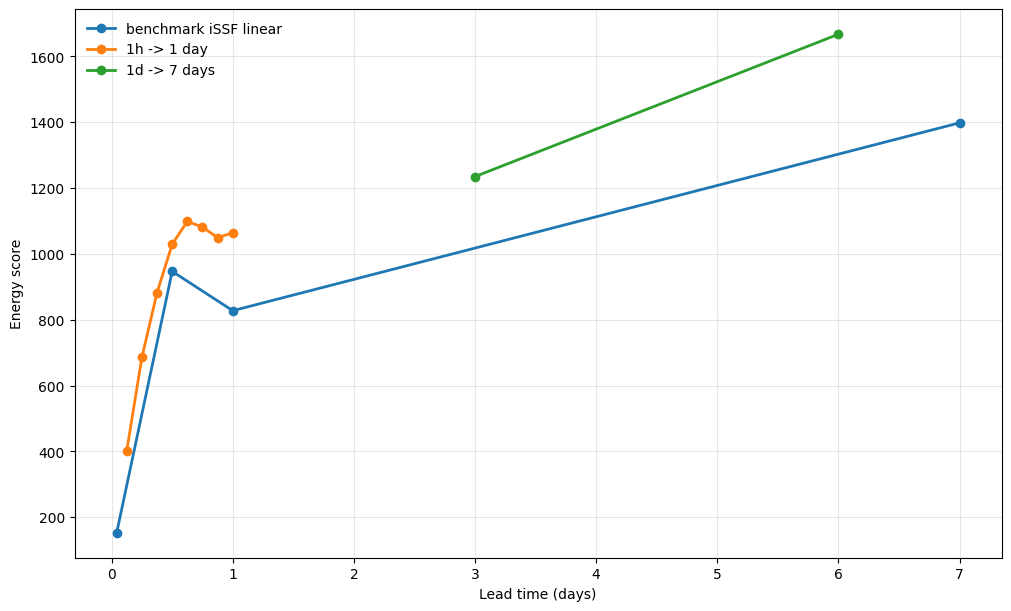

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)

for curve, group in comparison_df.groupby("curve", sort=False):
    group = group.sort_values("days")
    ax.plot(group["days"], group["energy_score"], marker="o", linewidth=2, label=curve)
    
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Energy score")
# ax.set_title(f"Recursive forecasting energy score: {STUDY_ID}")
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)
plt.show()


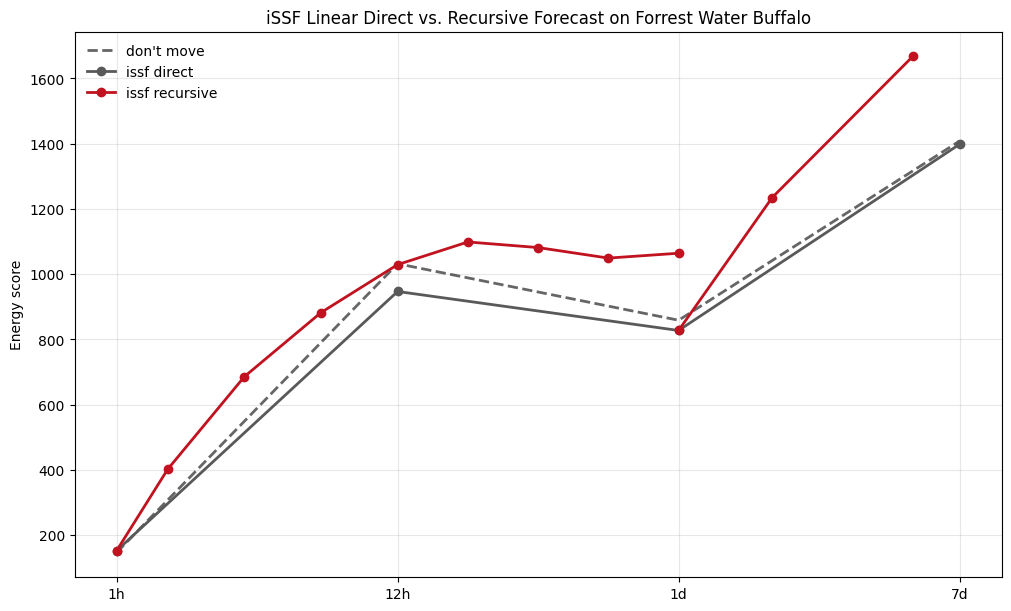

In [20]:
from pathlib import Path
import numpy as np


RUNS_ROOT = REPO_ROOT / "results" / "bench" / "runs"


def _latest_run_dir(study_id: str, timescale: str, method: str, covariate_set: str = "all") -> Path:
    candidates = sorted(
        RUNS_ROOT.glob(
            f"study={study_id}__ts={timescale}__cov={covariate_set}__method={method}__seed=0__k=*"
        )
    )
    candidates = [
        run_dir
        for run_dir in candidates
        if any((run_dir / "final_metrics" / split_key / "energy_by_step.csv.gz").exists() for split_key in HELD_OUT_SPLITS)
    ]
    if not candidates:
        raise ValueError(f"No completed run found for {study_id=} {timescale=} {method=}")
    return max(
        candidates,
        key=lambda run_dir: max(
            (run_dir / "final_metrics" / split_key / "summary.json").stat().st_mtime
            for split_key in HELD_OUT_SPLITS
            if (run_dir / "final_metrics" / split_key / "summary.json").exists()
        ),
    )


def _weighted_mean_energy(run_dir: Path) -> float:
    values = []
    counts = []
    for split_key in HELD_OUT_SPLITS:
        energy_path = run_dir / "final_metrics" / split_key / "energy_by_step.csv.gz"
        if not energy_path.exists():
            continue
        energy_df = pd.read_csv(energy_path, usecols=["energy_score"])
        values.append(float(energy_df["energy_score"].mean()))
        counts.append(int(len(energy_df)))
    return float(np.average(values, weights=counts))


baseline_nomove_by_timescale = {
    timescale: _weighted_mean_energy(_latest_run_dir(STUDY_ID, timescale, "baseline_nomove"))
    for timescale in ["1h", "12h", "1d", "7d"]
}
anchor_days = np.asarray([1.0 / 24.0, 0.5, 1.0, 7.0], dtype=float)
anchor_x = np.arange(len(anchor_days), dtype=float)
anchor_labels = ["1h", "12h", "1d", "7d"]


def _lead_time_to_even_x(days: pd.Series | np.ndarray) -> np.ndarray:
    return np.interp(np.asarray(days, dtype=float), anchor_days, anchor_x)


direct_df = comparison_df[comparison_df["curve"] == "benchmark iSSF linear"].copy()
nomove_df = pd.DataFrame(
    {
        "timescale": ["1h", "12h", "1d", "7d"],
        "days": [1.0 / 24.0, 0.5, 1.0, 7.0],
        "energy_score": [baseline_nomove_by_timescale[timescale] for timescale in ["1h", "12h", "1d", "7d"]],
    }
)
recursive_start_timescale = {
    "1h -> 1 day": "1h",
    "1d -> 7 days": "1d",
}
recursive_plot_df = []
for curve_name, start_timescale in recursive_start_timescale.items():
    recursive_df = comparison_df[comparison_df["curve"] == curve_name].copy().sort_values("days")
    start_row = direct_df[direct_df["timescale"] == start_timescale].iloc[[0]][
        ["days", "energy_score"]
    ].copy()
    start_row["curve"] = curve_name
    recursive_plot_df.append(
        pd.concat(
            [start_row, recursive_df[["curve", "days", "energy_score"]]],
            ignore_index=True,
        )
    )
recursive_plot_df = pd.concat(recursive_plot_df, ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
ax.plot(
    _lead_time_to_even_x(nomove_df.sort_values("days")["days"]),
    nomove_df.sort_values("days")["energy_score"],
    linewidth=2,
    linestyle="--",
    color="black",
    alpha=0.6,
    label="don't move",
)
ax.plot(
    _lead_time_to_even_x(direct_df.sort_values("days")["days"]),
    direct_df.sort_values("days")["energy_score"],
    marker="o",
    linewidth=2,
    color="0.35",
    label="issf direct",
)
for idx, (curve_name, group) in enumerate(recursive_plot_df.groupby("curve", sort=False)):
    group = group.sort_values("days")
    ax.plot(
        _lead_time_to_even_x(group["days"]),
        group["energy_score"],
        marker="o",
        linewidth=2,
        color="#c1121f",
        label="issf recursive" if idx == 0 else None,
    )

ax.set_ylabel("Energy score")
ax.set_xticks(anchor_x, anchor_labels)
ax.grid(True, alpha=0.3)
ax.legend(frameon=False)

ax.set_title('iSSF Linear Direct vs. Recursive Forecast on Forrest Water Buffalo')

plt.show()
